In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
from xgboost import XGBClassifier

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score

In [6]:
df = pd.read_csv("/home/patel-krish/anaconda3/BrainyBeam/heart.csv")

df = df.drop_duplicates().reset_index(drop=True)

X = df.drop(columns=["target"])
y = df["target"]

if y.isna().any() or X.isna().any().any():
    raise ValueError("Handle missing values before training.")

if y.nunique() != 2:
    raise ValueError("This implementation requires a binary target.")

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 241
Testing records: 61


In [7]:
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000, random_state=42)
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ),

    "SVM": make_pipeline(
        StandardScaler(),
        SVC(
            kernel="rbf",
            probability=True,
            random_state=42
        )
    ),

    "XGBoost": XGBClassifier(
        n_estimators=400,
        max_depth=2,
        learning_rate=0.08,
        subsample=0.75,
        colsample_bytree=1.0,
        min_child_weight=5,
        gamma=0.05,
        reg_alpha=0.1,
        reg_lambda=10.0,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        random_state=42,
        n_jobs=1
    )
}

In [8]:
def calculate_rates(y_true, y_scores, threshold):
    y_true = np.asarray(y_true)
    y_scores = np.asarray(y_scores)

    y_pred = (y_scores >= threshold).astype(int)

    TP = np.sum((y_true == 1) & (y_pred == 1))
    TN = np.sum((y_true == 0) & (y_pred == 0))
    FP = np.sum((y_true == 0) & (y_pred == 1))
    FN = np.sum((y_true == 1) & (y_pred == 0))

    TPR = TP / (TP + FN) if (TP + FN) > 0 else 0.0

    FPR = FP / (FP + TN) if (FP + TN) > 0 else 0.0

    return {
        "threshold": threshold,
        "TP": int(TP),
        "TN": int(TN),
        "FP": int(FP),
        "FN": int(FN),
        "TPR": TPR,
        "FPR": FPR
    }

In [9]:
def manual_roc_auc(y_true, y_scores):
    y_true = np.asarray(y_true)
    y_scores = np.asarray(y_scores)

    
    thresholds = np.concatenate((
        [np.inf],
        np.sort(np.unique(y_scores))[::-1],
        [-np.inf]
    ))

    positive_count = np.sum(y_true == 1)
    negative_count = np.sum(y_true == 0)

    if positive_count == 0 or negative_count == 0:
        raise ValueError(
            "Both positive and negative examples are required."
        )

    fpr_values = []
    tpr_values = []

    for threshold in thresholds:
        predicted = (y_scores >= threshold).astype(int)

        TP = np.sum((y_true == 1) & (predicted == 1))
        FP = np.sum((y_true == 0) & (predicted == 1))
        FN = np.sum((y_true == 1) & (predicted == 0))
        TN = np.sum((y_true == 0) & (predicted == 0))

        TPR = TP / (TP + FN)
        FPR = FP / (FP + TN)

        tpr_values.append(TPR)
        fpr_values.append(FPR)

    fpr_values = np.asarray(fpr_values)
    tpr_values = np.asarray(tpr_values)

    order = np.argsort(fpr_values, kind="stable")
    fpr_values = fpr_values[order]
    tpr_values = tpr_values[order]

    
    auc_score = np.sum(
        np.diff(fpr_values)
        * (tpr_values[:-1] + tpr_values[1:])
        / 2.0
    )

    return fpr_values, tpr_values, auc_score

In [10]:
roc_results = {}
summary = []
threshold_results = []

thresholds_to_check = [0.30, 0.50, 0.70]

for name, model in models.items():

    print(f"\nTraining {name}...")

    model.fit(X_train, y_train)

    if hasattr(model, "predict_proba"):
        y_scores = model.predict_proba(X_test)[:, 1]
    else:
        y_scores = model.decision_function(X_test)

    fpr, tpr, auc_value = manual_roc_auc(
        y_test,
        y_scores
    )

    y_pred = model.predict(X_test)

    roc_results[name] = {
        "FPR": fpr,
        "TPR": tpr,
        "AUC": auc_value
    }

    summary.append({
        "Model": name,
        "Manual AUC": auc_value,
        "Accuracy": accuracy_score(y_test, y_pred),
        "F1 Score": f1_score(
            y_test, y_pred, zero_division=0
        )
    })

    for threshold in thresholds_to_check:
        rates = calculate_rates(
            y_test,
            y_scores,
            threshold
        )

        threshold_results.append({
            "Model": name,
            **rates
        })


Training Logistic Regression...

Training Decision Tree...

Training Random Forest...

Training SVM...

Training XGBoost...


In [11]:
summary_df = pd.DataFrame(summary)

summary_df = summary_df.sort_values(
    "Manual AUC",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 75)
print("MODEL PERFORMANCE COMPARISON")
print("=" * 75)

print(summary_df.round(4).to_string(index=False))


MODEL PERFORMANCE COMPARISON
              Model  Manual AUC  Accuracy  F1 Score
            XGBoost      0.8820    0.7705    0.7879
Logistic Regression      0.8712    0.8033    0.8235
      Random Forest      0.8658    0.7869    0.8000
                SVM      0.8420    0.7705    0.7941
      Decision Tree      0.8317    0.7705    0.7812


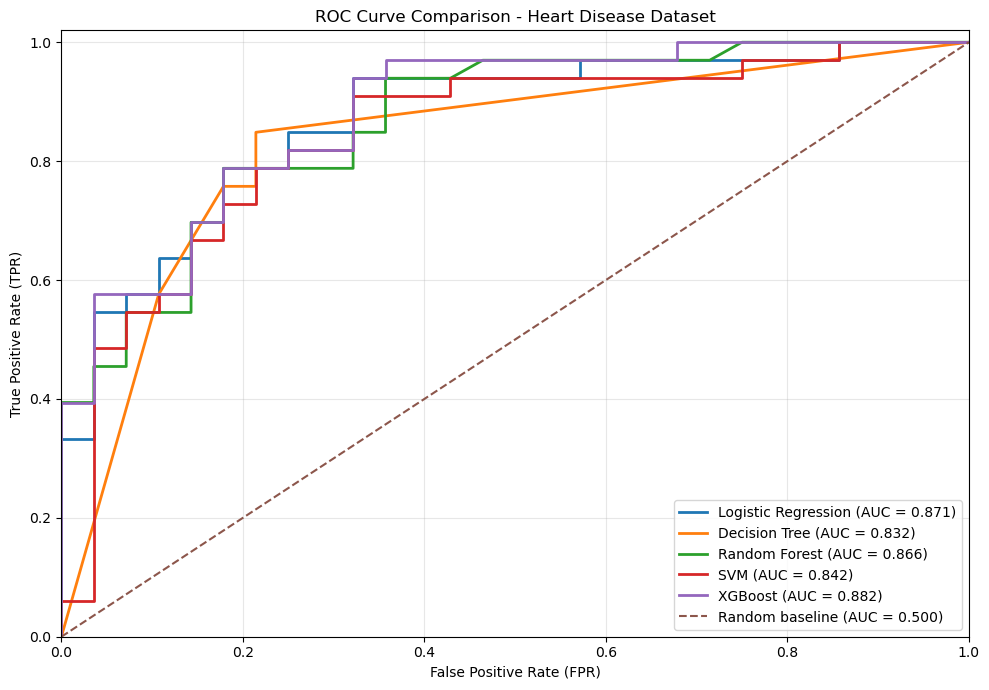

In [12]:
plt.figure(figsize=(10, 7))

for name, result in roc_results.items():
    plt.plot(
        result["FPR"],
        result["TPR"],
        linewidth=2,
        label=f"{name} (AUC = {result['AUC']:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random baseline (AUC = 0.500)"
)

plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.title("ROC Curve Comparison - Heart Disease Dataset")

plt.xlim(0, 1)
plt.ylim(0, 1.02)
plt.grid(True, alpha=0.3)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("manual_roc_comparison.png", dpi=300)
plt.show()

In [13]:
threshold_df = pd.DataFrame(threshold_results)

print("\n" + "=" * 75)
print("TPR AND FPR AT DIFFERENT CLASSIFICATION THRESHOLDS")
print("=" * 75)

print(
    threshold_df[
        ["Model", "threshold", "TP", "FP", "TN", "FN", "TPR", "FPR"]
    ].round(4).to_string(index=False)
)



summary_df.to_csv("manual_roc_auc_model_comparison.csv", index=False)
threshold_df.to_csv("manual_roc_threshold_comparison.csv", index=False)

print("\nSaved:")
print("1. manual_roc_comparison.png")
print("2. manual_roc_auc_model_comparison.csv")
print("3. manual_roc_threshold_comparison.csv")


TPR AND FPR AT DIFFERENT CLASSIFICATION THRESHOLDS
              Model  threshold  TP  FP  TN  FN    TPR    FPR
Logistic Regression        0.3  30   9  19   3 0.9091 0.3214
Logistic Regression        0.5  28   7  21   5 0.8485 0.2500
Logistic Regression        0.7  19   3  25  14 0.5758 0.1071
      Decision Tree        0.3  26   6  22   7 0.7879 0.2143
      Decision Tree        0.5  25   6  22   8 0.7576 0.2143
      Decision Tree        0.7  25   6  22   8 0.7576 0.2143
      Random Forest        0.3  30  10  18   3 0.9091 0.3571
      Random Forest        0.5  26   6  22   7 0.7879 0.2143
      Random Forest        0.7  18   4  24  15 0.5455 0.1429
                SVM        0.3  28   9  19   5 0.8485 0.3214
                SVM        0.5  27   8  20   6 0.8182 0.2857
                SVM        0.7  23   5  23  10 0.6970 0.1786
            XGBoost        0.3  28   9  19   5 0.8485 0.3214
            XGBoost        0.5  26   7  21   7 0.7879 0.2500
            XGBoost        0.7  2